# 03 — Data Preprocessing

## Objective

This notebook prepares the xView2 dataset for deep learning
model development.

The preprocessing pipeline will cover:

1. Dataset file indexing and integrity validation.
2. Image and target-mask consistency checks.
3. Image loading and datatype conversion.
4. Image normalization.
5. Target-mask encoding and validation.
6. Handling of unclassified annotations.
7. Paired image preprocessing.
8. Training-only data augmentation.
9. Preparation of PyTorch-compatible datasets.
10. Final preprocessing validation.

The official train, holdout, and test splits will be preserved.

No model training will be performed in this notebook.

In [1]:
# ============================================================
# 1. IMPORTS
# ============================================================

from pathlib import Path
from collections import Counter

import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader

# ============================================================
# 2. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_ROOT = PROJECT_ROOT / "dataset"

SPLITS = ["train", "hold", "test"]

print("Project Root:", PROJECT_ROOT)
print("Dataset Root:", DATASET_ROOT)

assert PROJECT_ROOT.exists()
assert DATASET_ROOT.exists()

for split in SPLITS:
    assert (DATASET_ROOT / split / "images").exists()
    assert (DATASET_ROOT / split / "labels").exists()
    assert (DATASET_ROOT / split / "targets").exists()

print("\nProject configuration completed.")

Project Root: d:\ML_Project
Dataset Root: d:\ML_Project\dataset

Project configuration completed.


In [2]:
# ============================================================
# 3. REPRODUCIBILITY
# ============================================================

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

# ============================================================
# 4. IMAGE CONFIGURATION
# ============================================================

IMAGE_HEIGHT = 1024
IMAGE_WIDTH = 1024

IMAGE_CHANNELS = 6

# ============================================================
# 5. DAMAGE CLASS CONFIGURATION
# ============================================================

CLASS_MAPPING = {
    0: "background",
    1: "no-damage",
    2: "minor-damage",
    3: "major-damage",
    4: "destroyed"
}

NUM_CLASSES = len(CLASS_MAPPING)

print("Random State:", RANDOM_STATE)
print("Image Dimensions:", IMAGE_HEIGHT, "x", IMAGE_WIDTH)
print("Input Channels:", IMAGE_CHANNELS)
print("Number of Classes:", NUM_CLASSES)

print("\nClass Mapping:")

for value, name in CLASS_MAPPING.items():
    print(f"{value}: {name}")

Random State: 42
Image Dimensions: 1024 x 1024
Input Channels: 6
Number of Classes: 5

Class Mapping:
0: background
1: no-damage
2: minor-damage
3: major-damage
4: destroyed


In [3]:
# ============================================================
# 6. DATASET FILE INDEXING
# ============================================================

def build_split_index(split):

    split_root = DATASET_ROOT / split

    images_dir = split_root / "images"
    targets_dir = split_root / "targets"
    labels_dir = split_root / "labels"

    pre_images = {
        p.stem.replace("_pre_disaster", ""): p
        for p in images_dir.glob("*_pre_disaster.png")
    }

    post_images = {
        p.stem.replace("_post_disaster", ""): p
        for p in images_dir.glob("*_post_disaster.png")
    }

    pre_masks = {
        p.stem.replace("_pre_disaster_target", ""): p
        for p in targets_dir.glob("*_pre_disaster_target.png")
    }

    post_masks = {
        p.stem.replace("_post_disaster_target", ""): p
        for p in targets_dir.glob("*_post_disaster_target.png")
    }

    pre_labels = {
        p.stem.replace("_pre_disaster", ""): p
        for p in labels_dir.glob("*_pre_disaster.json")
    }

    post_labels = {
        p.stem.replace("_post_disaster", ""): p
        for p in labels_dir.glob("*_post_disaster.json")
    }

    all_tile_ids = sorted(
        set(pre_images)
        | set(post_images)
        | set(pre_masks)
        | set(post_masks)
        | set(pre_labels)
        | set(post_labels)
    )

    records = []

    for tile_id in all_tile_ids:

        records.append({

            "tile_id": tile_id,

            "pre_image": pre_images.get(tile_id),
            "post_image": post_images.get(tile_id),

            "pre_mask": pre_masks.get(tile_id),
            "post_mask": post_masks.get(tile_id),

            "pre_label": pre_labels.get(tile_id),
            "post_label": post_labels.get(tile_id)

        })

    return pd.DataFrame(records)


# Build indexes for all official splits

split_indexes = {}

for split in SPLITS:

    split_indexes[split] = build_split_index(split)

    print(
        f"{split.upper()}:",
        len(split_indexes[split]),
        "indexed tiles"
    )

# Display training index

display(split_indexes["train"].head())

TRAIN: 2799 indexed tiles
HOLD: 933 indexed tiles
TEST: 933 indexed tiles


,tile_id,pre_image,post_image,pre_mask,post_mask,pre_label,post_label
0,guatemala-volcano_00000000,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\labels\guatemala-v...,d:\ML_Project\dataset\train\labels\guatemala-v...
1,guatemala-volcano_00000001,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\labels\guatemala-v...,d:\ML_Project\dataset\train\labels\guatemala-v...
2,guatemala-volcano_00000002,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\labels\guatemala-v...,d:\ML_Project\dataset\train\labels\guatemala-v...
3,guatemala-volcano_00000006,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\labels\guatemala-v...,d:\ML_Project\dataset\train\labels\guatemala-v...
4,guatemala-volcano_00000007,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\images\guatemala-v...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\targets\guatemala-...,d:\ML_Project\dataset\train\labels\guatemala-v...,d:\ML_Project\dataset\train\labels\guatemala-v...


In [4]:
# ============================================================
# 7. DATASET COMPLETENESS VALIDATION
# ============================================================

required_columns = [
    "pre_image",
    "post_image",
    "pre_mask",
    "post_mask",
    "pre_label",
    "post_label"
]

for split, df in split_indexes.items():

    print("\n" + "=" * 60)
    print(f"{split.upper()} COMPLETENESS")
    print("=" * 60)

    missing_summary = df[required_columns].isna().sum()

    display(missing_summary.to_frame(
        name="Missing Files"
    ))

    print("Total indexed tiles:", len(df))

    print(
        "Complete tiles:",
        (~df[required_columns].isna().any(axis=1)).sum()
    )


TRAIN COMPLETENESS


,Missing Files
pre_image,0
post_image,0
pre_mask,0
post_mask,0
pre_label,0
post_label,0


Total indexed tiles: 2799
Complete tiles: 2799

HOLD COMPLETENESS


,Missing Files
pre_image,0
post_image,0
pre_mask,0
post_mask,0
pre_label,0
post_label,0


Total indexed tiles: 933
Complete tiles: 933

TEST COMPLETENESS


,Missing Files
pre_image,0
post_image,0
pre_mask,0
post_mask,0
pre_label,0
post_label,0


Total indexed tiles: 933
Complete tiles: 933


## 8. Image and Target Mask Inspection

This section examines the actual image and target-mask
properties before preprocessing.

We will inspect:

- Image dimensions
- Image color modes
- Image data types
- Target mask dimensions
- Target mask color modes
- Unique pixel values
- Pixel-value distributions

The purpose is to establish the correct image
normalization and segmentation-mask encoding strategy.

In [5]:
# ============================================================
# 8. IMAGE AND MASK INSPECTION
# ============================================================

def inspect_sample(split, sample_index=0):

    df = split_indexes[split]

    sample = df.iloc[sample_index]

    print("\n" + "=" * 65)
    print(f"SPLIT: {split.upper()}")
    print("Tile ID:", sample["tile_id"])
    print("=" * 65)

    files = {
        "Pre Image": sample["pre_image"],
        "Post Image": sample["post_image"],
        "Pre Mask": sample["pre_mask"],
        "Post Mask": sample["post_mask"]
    }

    for name, filepath in files.items():

        with Image.open(filepath) as img:

            array = np.array(img)

            print(f"\n{name}")
            print("-" * 40)

            print("File:", filepath.name)
            print("Dimensions:", img.size)
            print("Mode:", img.mode)
            print("Array Shape:", array.shape)
            print("Data Type:", array.dtype)

            if "Mask" in name:

                unique_values, counts = np.unique(
                    array.reshape(-1, array.shape[-1])
                    if array.ndim == 3
                    else array,
                    return_counts=True,
                    axis=0 if array.ndim == 3 else None
                )

                print("Unique Pixel Values:", len(unique_values))
                print("Sample Values:", unique_values[:20])

            else:

                print("Minimum Pixel Value:", array.min())
                print("Maximum Pixel Value:", array.max())


# Inspect one sample from each split

for split in SPLITS:

    inspect_sample(split)


SPLIT: TRAIN
Tile ID: guatemala-volcano_00000000

Pre Image
----------------------------------------
File: guatemala-volcano_00000000_pre_disaster.png
Dimensions: (1024, 1024)
Mode: RGB
Array Shape: (1024, 1024, 3)
Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 255

Post Image
----------------------------------------
File: guatemala-volcano_00000000_post_disaster.png
Dimensions: (1024, 1024)
Mode: RGB
Array Shape: (1024, 1024, 3)
Data Type: uint8
Minimum Pixel Value: 4
Maximum Pixel Value: 255

Pre Mask
----------------------------------------
File: guatemala-volcano_00000000_pre_disaster_target.png
Dimensions: (1024, 1024)
Mode: L
Array Shape: (1024, 1024)
Data Type: uint8
Unique Pixel Values: 2
Sample Values: [0 1]

Post Mask
----------------------------------------
File: guatemala-volcano_00000000_post_disaster_target.png
Dimensions: (1024, 1024)
Mode: L
Array Shape: (1024, 1024)
Data Type: uint8
Unique Pixel Values: 2
Sample Values: [0 1]

SPLIT: HOLD
Tile ID: guatem

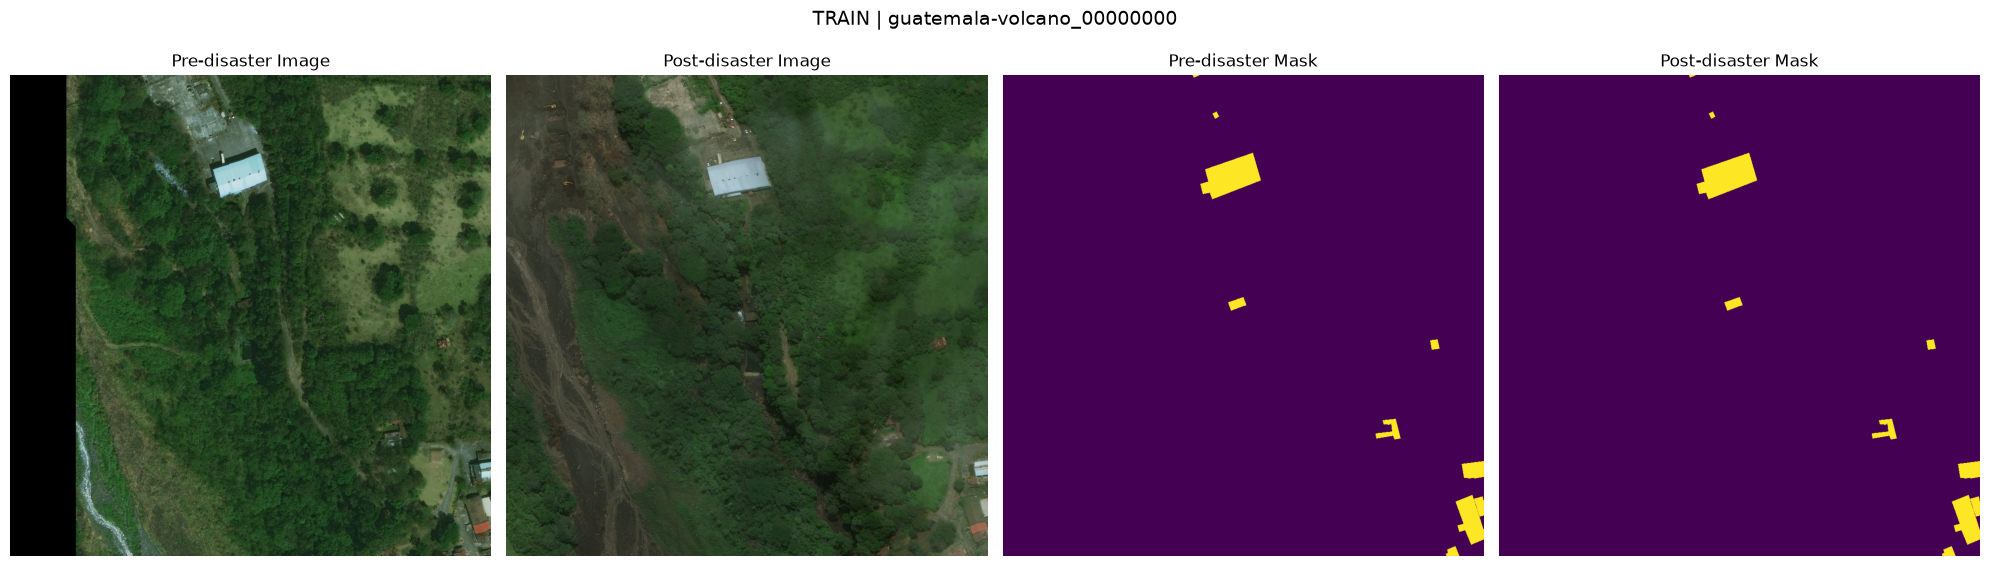

In [6]:
# ============================================================
# 9. VISUAL INSPECTION
# ============================================================

def visualize_sample(split, sample_index=0):

    sample = split_indexes[split].iloc[sample_index]

    fig, axes = plt.subplots(1, 4, figsize=(20, 6))

    files = [
        ("Pre-disaster Image", sample["pre_image"]),
        ("Post-disaster Image", sample["post_image"]),
        ("Pre-disaster Mask", sample["pre_mask"]),
        ("Post-disaster Mask", sample["post_mask"])
    ]

    for ax, (title, filepath) in zip(axes, files):

        img = Image.open(filepath)

        ax.imshow(np.array(img))
        ax.set_title(title)
        ax.axis("off")

    plt.suptitle(
        f"{split.upper()} | {sample['tile_id']}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


visualize_sample("train")

In [7]:
# ============================================================
# 10. MASK ENCODING CONFIGURATION
# ============================================================

# Pre-disaster building footprint mask
PRE_MASK_MAPPING = {
    0: "background",
    1: "building"
}

# Post-disaster damage segmentation mask
POST_MASK_MAPPING = {
    0: "background_or_unlabelled",
    1: "no-damage",
    2: "minor-damage",
    3: "major-damage",
    4: "destroyed"
}

DAMAGE_CLASSES = {
    1: "no-damage",
    2: "minor-damage",
    3: "major-damage",
    4: "destroyed"
}

NUM_DAMAGE_CLASSES = 4
BACKGROUND_CLASS = 0

print("Pre-mask mapping:")
print(PRE_MASK_MAPPING)

print("\nPost-mask mapping:")
print(POST_MASK_MAPPING)

print("\nNumber of damage categories:", NUM_DAMAGE_CLASSES)

Pre-mask mapping:
{0: 'background', 1: 'building'}

Post-mask mapping:
{0: 'background_or_unlabelled', 1: 'no-damage', 2: 'minor-damage', 3: 'major-damage', 4: 'destroyed'}

Number of damage categories: 4


In [8]:
# ============================================================
# 11. MASK PIXEL DISTRIBUTION AUDIT
# ============================================================

SAMPLES_PER_SPLIT = 100

rng = np.random.default_rng(RANDOM_STATE)

mask_distribution = []

for split, df in split_indexes.items():

    sample_size = min(SAMPLES_PER_SPLIT, len(df))

    selected_indices = rng.choice(
        len(df),
        size=sample_size,
        replace=False
    )

    selected_df = df.iloc[selected_indices]

    for _, sample in selected_df.iterrows():

        for mask_type, mask_column in [
            ("Pre", "pre_mask"),
            ("Post", "post_mask")
        ]:

            mask = np.array(
                Image.open(sample[mask_column])
            )

            values, counts = np.unique(
                mask,
                return_counts=True
            )

            for value, count in zip(values, counts):

                mask_distribution.append({

                    "split": split,
                    "tile_id": sample["tile_id"],
                    "mask_type": mask_type,
                    "pixel_value": int(value),
                    "pixel_count": int(count)

                })


mask_distribution_df = pd.DataFrame(mask_distribution)

print("Mask audit completed.")

print("Tiles inspected:", SAMPLES_PER_SPLIT * len(SPLITS))

print("\nObserved pixel values:")

display(
    mask_distribution_df.groupby(
        ["split", "mask_type", "pixel_value"]
    )["pixel_count"]
    .sum()
    .unstack(fill_value=0)
)

Mask audit completed.
Tiles inspected: 300

Observed pixel values:


pixel_value             0        1       2       3       4
split mask_type                                           
hold  Post       98671880  4952170  454214  475690  303646
      Pre        98647622  6209978       0       0       0
test  Post       99170323  4000424  991804  389278  305771
      Pre        99006376  5851224       0       0       0
train Post       98912443  4694107  252807  663023  335220
      Pre        98848712  6008888       0       0       0

In [9]:
# ============================================================
# 12. MASK VALUE VALIDATION
# ============================================================

EXPECTED_PRE_VALUES = set(PRE_MASK_MAPPING.keys())

EXPECTED_POST_VALUES = set(POST_MASK_MAPPING.keys())

for split in SPLITS:

    split_data = mask_distribution_df[
        mask_distribution_df["split"] == split
    ]

    for mask_type, expected_values in [
        ("Pre", EXPECTED_PRE_VALUES),
        ("Post", EXPECTED_POST_VALUES)
    ]:

        observed_values = set(
            split_data.loc[
                split_data["mask_type"] == mask_type,
                "pixel_value"
            ].unique()
        )

        unexpected = observed_values - expected_values

        print(f"\n{split.upper()} — {mask_type} MASK")

        print("Observed:", sorted(observed_values))
        print("Unexpected:", sorted(unexpected))

        assert not unexpected, (
            f"Unexpected values in {split} {mask_type} masks"
        )

print("\nAll sampled masks contain valid pixel values.")


TRAIN — Pre MASK
Observed: [np.int64(0), np.int64(1)]
Unexpected: []

TRAIN — Post MASK
Observed: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Unexpected: []

HOLD — Pre MASK
Observed: [np.int64(0), np.int64(1)]
Unexpected: []

HOLD — Post MASK
Observed: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Unexpected: []

TEST — Pre MASK
Observed: [np.int64(0), np.int64(1)]
Unexpected: []

TEST — Post MASK
Observed: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Unexpected: []

All sampled masks contain valid pixel values.


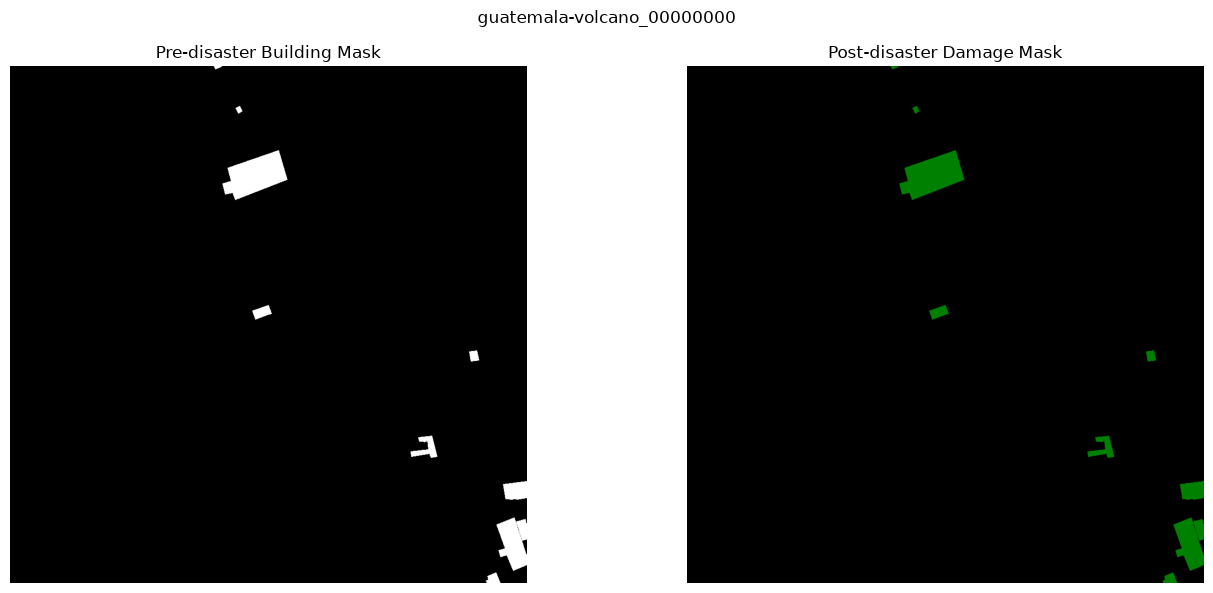

In [10]:
# ============================================================
# 13. DAMAGE MASK VISUALIZATION
# ============================================================

from matplotlib.colors import ListedColormap, BoundaryNorm

damage_cmap = ListedColormap([
    "black",       # 0: Background / unlabelled
    "green",       # 1: No damage
    "yellow",      # 2: Minor damage
    "orange",      # 3: Major damage
    "red"          # 4: Destroyed
])

damage_norm = BoundaryNorm(
    np.arange(-0.5, 5.5, 1),
    damage_cmap.N
)


def visualize_damage_mask(split, sample_index=0):

    sample = split_indexes[split].iloc[sample_index]

    pre_mask = np.array(
        Image.open(sample["pre_mask"])
    )

    post_mask = np.array(
        Image.open(sample["post_mask"])
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].imshow(pre_mask, cmap="gray", vmin=0, vmax=1)

    axes[0].set_title("Pre-disaster Building Mask")

    axes[1].imshow(
        post_mask,
        cmap=damage_cmap,
        norm=damage_norm
    )

    axes[1].set_title("Post-disaster Damage Mask")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(sample["tile_id"])

    plt.tight_layout()
    plt.show()


visualize_damage_mask("train")

## 14. Unclassified Annotation Investigation

The previous EDA identified unclassified building annotations.

This section investigates whether unclassified building polygons
are represented as zero-valued pixels in the post-disaster masks.

We will:

1. Count annotation subtypes in each split.
2. Identify tiles containing unclassified buildings.
3. Rasterize unclassified building polygons.
4. Compare their locations against the post-disaster target masks.

This will help determine the correct treatment of unclassified
pixels during segmentation training.

In [11]:
# ============================================================
# 14.1 ANNOTATION SUBTYPE AUDIT
# ============================================================

annotation_counts = []

for split, df in split_indexes.items():

    for _, sample in df.iterrows():

        with open(sample["post_label"], "r") as f:
            data = json.load(f)

        buildings = data.get("features", {}).get("xy", [])

        for building in buildings:

            properties = building.get("properties", {})

            if properties.get("feature_type") != "building":
                continue

            annotation_counts.append({

                "split": split,
                "tile_id": sample["tile_id"],
                "subtype": properties.get("subtype")

            })


annotation_df = pd.DataFrame(annotation_counts)

subtype_summary = pd.crosstab(
    annotation_df["split"],
    annotation_df["subtype"],
    margins=True
)

display(subtype_summary)

print("\nUnclassified building counts:")

print(
    annotation_df[
        annotation_df["subtype"] == "un-classified"
    ].groupby("split").size()
)

subtype,destroyed,major-damage,minor-damage,no-damage,un-classified,All
split,,,,,,
hold,4223,4605,6338,37971,1255,54392
test,3775,3850,4798,41427,1012,54862
train,13227,14161,14980,117426,2993,162787
All,21225,22616,26116,196824,5260,272041



Unclassified building counts:
split
hold     1255
test     1012
train    2993
dtype: int64


In [13]:
# ============================================================
# 14.2 EXHAUSTIVE UNCLASSIFIED POLYGON-MASK AUDIT
# ============================================================

unclassified_results = []

for split, df in split_indexes.items():

    split_unclassified = set(
        annotation_df.loc[
            (annotation_df["split"] == split) &
            (annotation_df["subtype"] == "un-classified"),
            "tile_id"
        ]
    )

    print(f"\nProcessing {split.upper()}: "
          f"{len(split_unclassified)} tiles")

    for tile_id in sorted(split_unclassified):

        sample = df.loc[
            df["tile_id"] == tile_id
        ].iloc[0]

        with open(sample["post_label"], "r") as f:
            data = json.load(f)

        geometries = []

        for feature in data.get("features", {}).get("xy", []):

            properties = feature.get("properties", {})

            if (
                properties.get("feature_type") == "building"
                and properties.get("subtype") == "un-classified"
            ):

                try:
                    geom = wkt.loads(feature["wkt"])

                    if not geom.is_empty and geom.is_valid:
                        geometries.append((geom, 1))

                except Exception:
                    continue

        if not geometries:
            continue

        unclassified_mask = rasterize(
            geometries,
            out_shape=(IMAGE_HEIGHT, IMAGE_WIDTH),
            transform=Affine.identity(),
            fill=0,
            dtype=np.uint8
        )

        post_mask = np.array(
            Image.open(sample["post_mask"])
        )

        polygon_pixels = post_mask[unclassified_mask == 1]

        values, counts = np.unique(
            polygon_pixels,
            return_counts=True
        )

        pixel_counts = dict(zip(values, counts))

        total_pixels = len(polygon_pixels)
        zero_pixels = pixel_counts.get(0, 0)

        unclassified_results.append({

            "split": split,
            "tile_id": tile_id,
            "unclassified_polygons": len(geometries),
            "polygon_pixels": total_pixels,
            "zero_pixels": zero_pixels,
            "nonzero_pixels": total_pixels - zero_pixels

        })


exhaustive_audit_df = pd.DataFrame(unclassified_results)

print("\nEXHAUSTIVE AUDIT SUMMARY")

summary = exhaustive_audit_df.groupby("split")[
    [
        "unclassified_polygons",
        "polygon_pixels",
        "zero_pixels",
        "nonzero_pixels"
    ]
].sum()

display(summary)

total_polygon_pixels = summary["polygon_pixels"].sum()
total_zero_pixels = summary["zero_pixels"].sum()

print(
    "\nOverall zero correspondence:",
    f"{100 * total_zero_pixels / total_polygon_pixels:.6f}%"
)

print(
    "Tiles audited:",
    len(exhaustive_audit_df)
)


Processing TRAIN: 683 tiles

Processing HOLD: 258 tiles

Processing TEST: 231 tiles

EXHAUSTIVE AUDIT SUMMARY


,unclassified_polygons,polygon_pixels,zero_pixels,nonzero_pixels
split,,,,
hold,1255,906262,906148,114
test,1012,667145,667063,82
train,2993,1455303,1454878,425



Overall zero correspondence: 99.979496%
Tiles audited: 1172


In [14]:
# ============================================================
# 16. NONZERO PIXEL INVESTIGATION
# ============================================================

nonzero_overlap_results = []

for split, df in split_indexes.items():

    tile_ids = exhaustive_audit_df.loc[
        exhaustive_audit_df["split"] == split,
        "tile_id"
    ]

    for tile_id in tile_ids:

        sample = df.loc[
            df["tile_id"] == tile_id
        ].iloc[0]

        with open(sample["post_label"], "r") as f:
            data = json.load(f)

        geometries = []

        for feature in data.get("features", {}).get("xy", []):

            properties = feature.get("properties", {})

            if (
                properties.get("feature_type") == "building"
                and properties.get("subtype") == "un-classified"
            ):

                try:
                    geom = wkt.loads(feature["wkt"])

                    if geom.is_valid and not geom.is_empty:
                        geometries.append((geom, 1))

                except Exception:
                    continue

        if not geometries:
            continue

        unclassified_mask = rasterize(
            geometries,
            out_shape=(IMAGE_HEIGHT, IMAGE_WIDTH),
            transform=Affine.identity(),
            fill=0,
            dtype=np.uint8
        )

        post_mask = np.array(
            Image.open(sample["post_mask"])
        )

        overlap_values = post_mask[
            (unclassified_mask == 1) & (post_mask != 0)
        ]

        if len(overlap_values) > 0:

            values, counts = np.unique(
                overlap_values,
                return_counts=True
            )

            for value, count in zip(values, counts):

                nonzero_overlap_results.append({

                    "split": split,
                    "tile_id": tile_id,
                    "damage_class": int(value),
                    "pixel_count": int(count)

                })


overlap_df = pd.DataFrame(nonzero_overlap_results)

if not overlap_df.empty:

    print("Nonzero pixel distribution:")

    display(
        overlap_df.groupby(
            ["split", "damage_class"]
        )["pixel_count"].sum().unstack(fill_value=0)
    )

    print("\nTiles with nonzero overlaps:",
          overlap_df["tile_id"].nunique())

    display(overlap_df.head(20))

else:

    print("No nonzero overlaps detected.")

Nonzero pixel distribution:


damage_class,1,2,3,4
split,,,,
hold,80,14,20,0
test,64,6,0,12
train,344,49,27,5



Tiles with nonzero overlaps: 55


,split,tile_id,damage_class,pixel_count
0,train,guatemala-volcano_00000025,4,5
1,train,hurricane-florence_00000028,1,4
2,train,hurricane-florence_00000060,1,4
3,train,hurricane-matthew_00000017,1,1
4,train,hurricane-matthew_00000023,1,3
5,train,hurricane-matthew_00000023,2,1
6,train,hurricane-matthew_00000043,3,1
7,train,hurricane-matthew_00000044,2,11
8,train,hurricane-matthew_00000048,2,2
9,train,hurricane-matthew_00000064,3,1


## 15. Target Mask Preparation

The post-disaster target masks contain five segmentation
classes, including background.

Unclassified building polygons are explicitly converted
to IGNORE_INDEX (255).

The original target masks remain unchanged.

The generated training targets will preserve genuine
background pixels and exclude unclassified regions
from the segmentation loss.

In [15]:
# ============================================================
# 15.1 PREPROCESSING CONFIGURATION
# ============================================================

from rasterio.features import rasterize
from affine import Affine
from shapely import wkt

NUM_CLASSES = 5
IGNORE_INDEX = 255

CLASS_MAPPING = {
    0: "background",
    1: "no-damage",
    2: "minor-damage",
    3: "major-damage",
    4: "destroyed"
}

IMAGE_SIZE = (1024, 1024)

print("Number of classes:", NUM_CLASSES)
print("Ignore index:", IGNORE_INDEX)
print("Image size:", IMAGE_SIZE)

Number of classes: 5
Ignore index: 255
Image size: (1024, 1024)


In [16]:
# ============================================================
# 15.2 GENERATE UNCLASSIFIED BUILDING MASK
# ============================================================

def generate_unclassified_mask(label_path):

    with open(label_path, "r") as f:
        data = json.load(f)

    geometries = []

    for feature in data.get("features", {}).get("xy", []):

        properties = feature.get("properties", {})

        if (
            properties.get("feature_type") == "building"
            and properties.get("subtype") == "un-classified"
        ):

            try:
                geom = wkt.loads(feature["wkt"])

                if not geom.is_empty and geom.is_valid:

                    geometries.append((geom, 1))

            except Exception:
                continue

    if not geometries:

        return np.zeros(IMAGE_SIZE, dtype=np.uint8)

    ignore_mask = rasterize(
        geometries,
        out_shape=IMAGE_SIZE,
        transform=Affine.identity(),
        fill=0,
        dtype=np.uint8,
        all_touched=False
    )

    return ignore_mask


print("Unclassified mask generation function ready.")

Unclassified mask generation function ready.


In [17]:
# ============================================================
# 15.3 GENERATE FINAL TARGET MASK
# ============================================================

def generate_target_mask(post_mask_path, post_label_path):

    # Load original post-disaster mask
    original_mask = np.array(
        Image.open(post_mask_path).convert("L")
    )

    # Validate original dimensions
    assert original_mask.shape == IMAGE_SIZE

    # Validate original class values
    valid_values = set(np.unique(original_mask))

    assert valid_values.issubset(set(CLASS_MAPPING.keys())), (
        f"Unexpected mask values: {valid_values}"
    )

    # Generate unclassified building regions
    ignore_mask = generate_unclassified_mask(post_label_path)

    # Copy original target
    target_mask = original_mask.copy()

    # Apply ignore index to unclassified buildings
    target_mask[ignore_mask == 1] = IGNORE_INDEX

    return target_mask

Split: TRAIN
Tile: guatemala-volcano_00000000

Original mask distribution:
0: 1,032,738
1: 15,838

Processed target distribution:
0: 1,032,738
1: 15,838

Target validation passed.


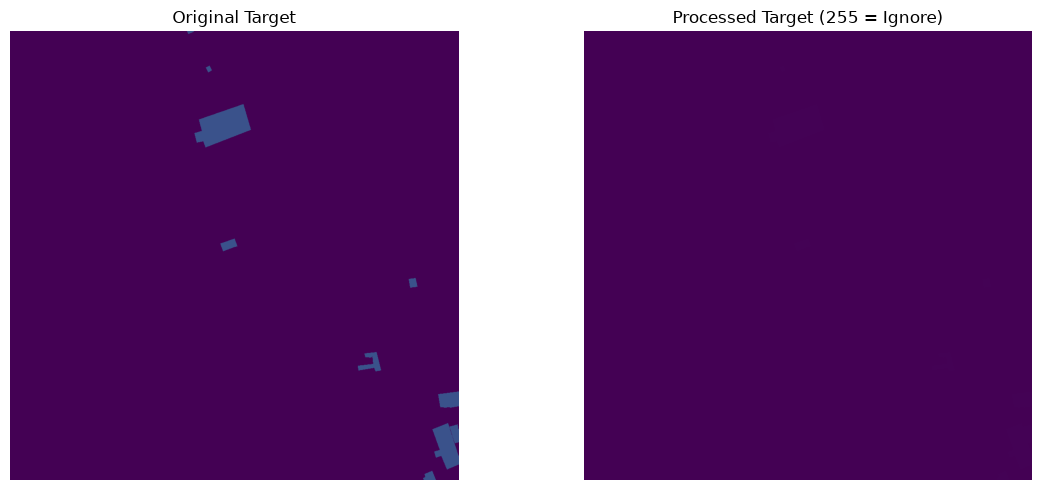

In [18]:
# ============================================================
# 15.4 TARGET MASK VALIDATION
# ============================================================

def inspect_target(split, sample_index=0):

    sample = split_indexes[split].iloc[sample_index]

    original_mask = np.array(
        Image.open(sample["post_mask"])
    )

    target_mask = generate_target_mask(
        sample["post_mask"],
        sample["post_label"]
    )

    print("Split:", split.upper())
    print("Tile:", sample["tile_id"])

    print("\nOriginal mask distribution:")

    values, counts = np.unique(
        original_mask,
        return_counts=True
    )

    for value, count in zip(values, counts):
        print(f"{value}: {count:,}")

    print("\nProcessed target distribution:")

    values, counts = np.unique(
        target_mask,
        return_counts=True
    )

    for value, count in zip(values, counts):
        print(f"{value}: {count:,}")

    assert target_mask.shape == IMAGE_SIZE

    assert set(np.unique(target_mask)).issubset(
        set(CLASS_MAPPING.keys()) | {IGNORE_INDEX}
    )

    print("\nTarget validation passed.")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(original_mask, cmap="viridis", vmin=0, vmax=4)
    axes[0].set_title("Original Target")

    axes[1].imshow(
        target_mask,
        cmap="viridis",
        vmin=0,
        vmax=255
    )
    axes[1].set_title("Processed Target (255 = Ignore)")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


inspect_target("train")

In [19]:
# ============================================================
# 16. IMAGE PREPROCESSING
# ============================================================

def preprocess_images(pre_image_path, post_image_path):

    pre_image = np.array(
        Image.open(pre_image_path).convert("RGB")
    )

    post_image = np.array(
        Image.open(post_image_path).convert("RGB")
    )

    assert pre_image.shape == (1024, 1024, 3)
    assert post_image.shape == (1024, 1024, 3)

    # Concatenate pre and post images
    combined_image = np.concatenate(
        [pre_image, post_image],
        axis=2
    )

    # Normalize pixel values to [0, 1]
    combined_image = combined_image.astype(
        np.float32
    ) / 255.0

    # Convert HWC to CHW
    combined_image = np.transpose(
        combined_image,
        (2, 0, 1)
    )

    return torch.from_numpy(
        np.ascontiguousarray(combined_image)
    )

In [20]:
# ============================================================
# 16.1 IMAGE PREPROCESSING VALIDATION
# ============================================================

sample = split_indexes["train"].iloc[0]

sample_image = preprocess_images(
    sample["pre_image"],
    sample["post_image"]
)

print("Image tensor shape:", sample_image.shape)
print("Image tensor dtype:", sample_image.dtype)

print("Minimum:", sample_image.min().item())
print("Maximum:", sample_image.max().item())

assert sample_image.shape == (6, 1024, 1024)
assert sample_image.dtype == torch.float32

assert sample_image.min() >= 0
assert sample_image.max() <= 1

print("\nImage preprocessing validation passed.")

Image tensor shape: torch.Size([6, 1024, 1024])
Image tensor dtype: torch.float32
Minimum: 0.0
Maximum: 1.0

Image preprocessing validation passed.


In [21]:
# ============================================================
# 17. PYTORCH DATASET
# ============================================================

class XView2Dataset(Dataset):

    def __init__(self, dataframe):

        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        sample = self.dataframe.iloc[index]

        # Preprocess six-channel input
        image = preprocess_images(
            sample["pre_image"],
            sample["post_image"]
        )

        # Prepare segmentation target
        target = generate_target_mask(
            sample["post_mask"],
            sample["post_label"]
        )

        target = torch.from_numpy(
            target.astype(np.int64)
        )

        return {
            "image": image,
            "mask": target,
            "tile_id": sample["tile_id"]
        }

In [22]:
# ============================================================
# 17.1 CREATE DATASET OBJECTS
# ============================================================

train_dataset = XView2Dataset(
    split_indexes["train"]
)

hold_dataset = XView2Dataset(
    split_indexes["hold"]
)

test_dataset = XView2Dataset(
    split_indexes["test"]
)

print("Training samples:", len(train_dataset))
print("Holdout samples:", len(hold_dataset))
print("Test samples:", len(test_dataset))

Training samples: 2799
Holdout samples: 933
Test samples: 933


In [23]:
# ============================================================
# 17.2 DATASET SAMPLE VALIDATION
# ============================================================

sample = train_dataset[0]

image_tensor = sample["image"]
target_tensor = sample["mask"]

print("Tile ID:", sample["tile_id"])

print("\nImage:")
print("Shape:", image_tensor.shape)
print("Datatype:", image_tensor.dtype)

print("\nTarget:")
print("Shape:", target_tensor.shape)
print("Datatype:", target_tensor.dtype)

print("\nTarget classes:")

values, counts = torch.unique(
    target_tensor,
    return_counts=True
)

for value, count in zip(values, counts):

    print(f"{value.item()}: {count.item():,}")

assert image_tensor.shape == (6, 1024, 1024)
assert target_tensor.shape == (1024, 1024)

assert image_tensor.dtype == torch.float32
assert target_tensor.dtype == torch.int64

assert set(values.tolist()).issubset(
    set(CLASS_MAPPING.keys()) | {IGNORE_INDEX}
)

print("\nPyTorch dataset validation passed.")

Tile ID: guatemala-volcano_00000000

Image:
Shape: torch.Size([6, 1024, 1024])
Datatype: torch.float32

Target:
Shape: torch.Size([1024, 1024])
Datatype: torch.int64

Target classes:
0: 1,032,738
1: 15,838

PyTorch dataset validation passed.


In [24]:
# ============================================================
# 18. VERIFY IGNORE-INDEX IMPLEMENTATION
# ============================================================

# Find a training tile containing unclassified annotations

candidate_ids = annotation_df.loc[
    (annotation_df["split"] == "train") &
    (annotation_df["subtype"] == "un-classified"),
    "tile_id"
].unique()

selected_sample = None
selected_target = None

for tile_id in candidate_ids:

    sample = split_indexes["train"].loc[
        split_indexes["train"]["tile_id"] == tile_id
    ].iloc[0]

    target = generate_target_mask(
        sample["post_mask"],
        sample["post_label"]
    )

    if np.any(target == IGNORE_INDEX):

        selected_sample = sample
        selected_target = target
        break


assert selected_sample is not None, (
    "No unclassified pixels were generated."
)

original_mask = np.array(
    Image.open(selected_sample["post_mask"])
)

print("Selected tile:", selected_sample["tile_id"])

print("\nOriginal mask distribution:")

values, counts = np.unique(
    original_mask,
    return_counts=True
)

for value, count in zip(values, counts):
    print(f"{value}: {count:,}")

print("\nProcessed target distribution:")

values, counts = np.unique(
    selected_target,
    return_counts=True
)

for value, count in zip(values, counts):
    print(f"{value}: {count:,}")

assert np.any(selected_target == 255)

assert np.all(
    selected_target[
        generate_unclassified_mask(
            selected_sample["post_label"]
        ) == 1
    ] == 255
)

print("\nIgnore-index validation passed.")

Selected tile: guatemala-volcano_00000025

Original mask distribution:
0: 1,040,041
3: 1,984
4: 6,551

Processed target distribution:
0: 979,513
3: 1,984
4: 6,546
255: 60,533

Ignore-index validation passed.


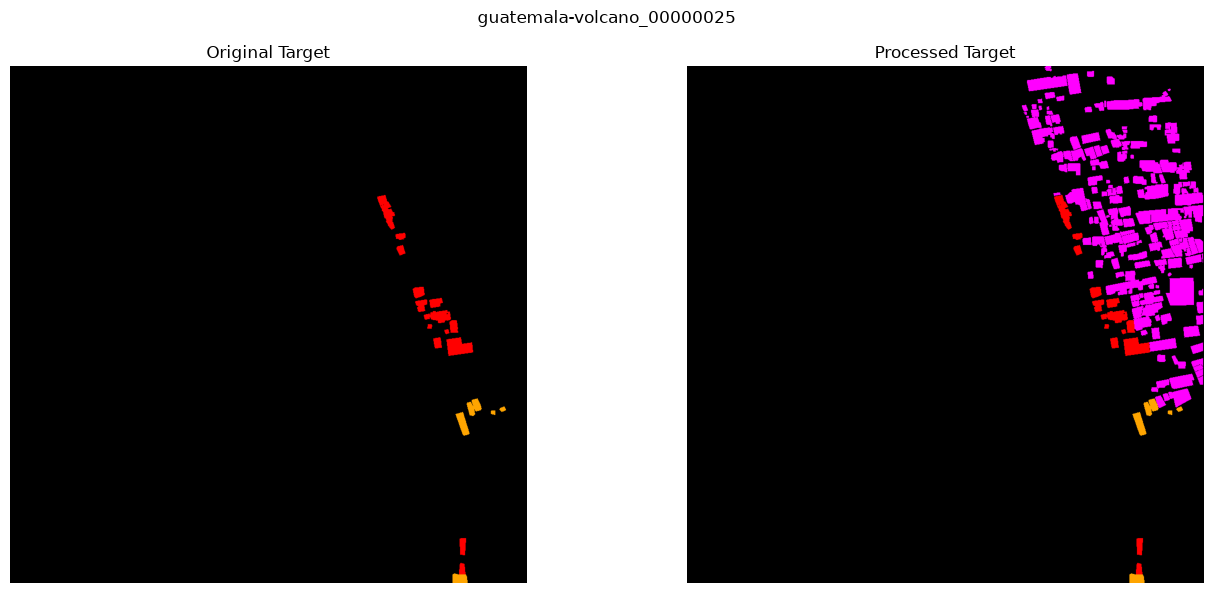

In [25]:
# ============================================================
# 18.1 CATEGORICAL TARGET VISUALIZATION
# ============================================================

from matplotlib.colors import ListedColormap, BoundaryNorm

target_cmap = ListedColormap([
    "black",       # 0 Background
    "green",       # 1 No damage
    "yellow",      # 2 Minor damage
    "orange",      # 3 Major damage
    "red",         # 4 Destroyed
    "magenta"      # 255 Ignore
])

target_bounds = [
    -0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 255.5
]

target_norm = BoundaryNorm(
    target_bounds,
    target_cmap.N
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(
    original_mask,
    cmap=target_cmap,
    norm=target_norm
)

axes[0].set_title("Original Target")

axes[1].imshow(
    selected_target,
    cmap=target_cmap,
    norm=target_norm
)

axes[1].set_title("Processed Target")

for ax in axes:
    ax.axis("off")

plt.suptitle(selected_sample["tile_id"])
plt.tight_layout()
plt.show()

## 19. Processed Target Caching

Generating ignore masks from JSON polygons is computationally
expensive when repeated during every training epoch.

This section generates the processed target masks once and
stores them separately.

The original dataset remains unchanged.

Cached masks retain:
- Background: 0
- No damage: 1
- Minor damage: 2
- Major damage: 3
- Destroyed: 4
- Ignore: 255

In [27]:
# ============================================================
# 19.1 TARGET MASK CACHING
# ============================================================

PROCESSED_ROOT = PROJECT_ROOT / "processed"

TARGET_CACHE_ROOT = PROCESSED_ROOT / "targets"

for split in SPLITS:

    cache_dir = TARGET_CACHE_ROOT / split
    cache_dir.mkdir(parents=True, exist_ok=True)

    df = split_indexes[split]

    print(f"\nProcessing {split.upper()}...")

    for index, (_, sample) in enumerate(df.iterrows(), start=1):

        cache_path = cache_dir / f"{sample['tile_id']}.png"

        # Skip already processed targets
        if cache_path.exists():
            continue

        target = generate_target_mask(
            sample["post_mask"],
            sample["post_label"]
        )

        Image.fromarray(
            target.astype(np.uint8),
            mode="L"
        ).save(cache_path)

        # Display progress every 100 samples
        if index % 100 == 0 or index == len(df):

            print(
                f"{split.upper()}: "
                f"{index}/{len(df)} processed"
            )

print("\nTarget mask caching completed.")
print("Cache directory:", TARGET_CACHE_ROOT)


Processing TRAIN...
TRAIN: 100/2799 processed
TRAIN: 200/2799 processed
TRAIN: 300/2799 processed
TRAIN: 400/2799 processed
TRAIN: 500/2799 processed
TRAIN: 600/2799 processed
TRAIN: 700/2799 processed
TRAIN: 800/2799 processed
TRAIN: 900/2799 processed
TRAIN: 1000/2799 processed
TRAIN: 1100/2799 processed
TRAIN: 1200/2799 processed
TRAIN: 1300/2799 processed
TRAIN: 1400/2799 processed
TRAIN: 1500/2799 processed
TRAIN: 1600/2799 processed
TRAIN: 1700/2799 processed
TRAIN: 1800/2799 processed
TRAIN: 1900/2799 processed
TRAIN: 2000/2799 processed
TRAIN: 2100/2799 processed
TRAIN: 2200/2799 processed
TRAIN: 2300/2799 processed
TRAIN: 2400/2799 processed
TRAIN: 2500/2799 processed
TRAIN: 2600/2799 processed
TRAIN: 2700/2799 processed
TRAIN: 2799/2799 processed

Processing HOLD...
HOLD: 100/933 processed
HOLD: 200/933 processed
HOLD: 300/933 processed
HOLD: 400/933 processed
HOLD: 500/933 processed
HOLD: 600/933 processed
HOLD: 700/933 processed
HOLD: 800/933 processed
HOLD: 900/933 proces

In [28]:
# ============================================================
# 19.2 CACHE INTEGRITY VALIDATION
# ============================================================

for split in SPLITS:

    df = split_indexes[split]

    cache_dir = TARGET_CACHE_ROOT / split

    cached_files = list(cache_dir.glob("*.png"))

    print(f"\n{split.upper()}")

    print("Expected:", len(df))
    print("Cached:", len(cached_files))

    assert len(cached_files) == len(df)

    # Check one cached target
    sample = df.iloc[0]

    cached_mask = np.array(
        Image.open(
            cache_dir / f"{sample['tile_id']}.png"
        )
    )

    original_generated = generate_target_mask(
        sample["post_mask"],
        sample["post_label"]
    )

    assert np.array_equal(
        cached_mask,
        original_generated
    )

    assert cached_mask.shape == IMAGE_SIZE

print("\nAll cached targets validated.")


TRAIN
Expected: 2799
Cached: 2799

HOLD
Expected: 933
Cached: 933

TEST
Expected: 933
Cached: 933

All cached targets validated.


In [29]:
# ============================================================
# 20. SYNCHRONIZED SPATIAL AUGMENTATION
# ============================================================

def augment_sample(image, mask):

    # Random horizontal flip
    if random.random() < 0.5:

        image = torch.flip(image, dims=[2])
        mask = torch.flip(mask, dims=[1])

    # Random vertical flip
    if random.random() < 0.5:

        image = torch.flip(image, dims=[1])
        mask = torch.flip(mask, dims=[0])

    # Random 90-degree rotation
    rotations = random.randint(0, 3)

    if rotations:

        image = torch.rot90(
            image,
            k=rotations,
            dims=[1, 2]
        )

        mask = torch.rot90(
            mask,
            k=rotations,
            dims=[0, 1]
        )

    return image.contiguous(), mask.contiguous()


print("Synchronized augmentation function ready.")

Synchronized augmentation function ready.


In [30]:
# ============================================================
# 20.1 AUGMENTATION VALIDATION
# ============================================================

sample = train_dataset[0]

image = sample["image"]
mask = sample["mask"]

aug_image, aug_mask = augment_sample(
    image.clone(),
    mask.clone()
)

print("Original image:", image.shape)
print("Augmented image:", aug_image.shape)

print("Original mask:", mask.shape)
print("Augmented mask:", aug_mask.shape)

print("\nOriginal mask classes:",
      torch.unique(mask).tolist())

print("Augmented mask classes:",
      torch.unique(aug_mask).tolist())

assert aug_image.shape == image.shape
assert aug_mask.shape == mask.shape

assert set(torch.unique(aug_mask).tolist()) == set(
    torch.unique(mask).tolist()
)

print("\nAugmentation validation passed.")

Original image: torch.Size([6, 1024, 1024])
Augmented image: torch.Size([6, 1024, 1024])
Original mask: torch.Size([1024, 1024])
Augmented mask: torch.Size([1024, 1024])

Original mask classes: [0, 1]
Augmented mask classes: [0, 1]

Augmentation validation passed.


In [31]:
# ============================================================
# 21. OPTIMIZED PYTORCH DATASET
# ============================================================

class XView2Dataset(Dataset):

    def __init__(self, dataframe, split, augment=False):

        self.dataframe = dataframe.reset_index(drop=True)
        self.split = split
        self.augment = augment

        self.cache_dir = TARGET_CACHE_ROOT / split

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        sample = self.dataframe.iloc[index]

        # Load six-channel image
        image = preprocess_images(
            sample["pre_image"],
            sample["post_image"]
        )

        # Load cached target
        target_path = (
            self.cache_dir / f"{sample['tile_id']}.png"
        )

        target_array = np.array(
            Image.open(target_path).convert("L")
        )

        target = torch.from_numpy(
            target_array.astype(np.int64)
        )

        # Apply augmentation only when enabled
        if self.augment:

            image, target = augment_sample(
                image,
                target
            )

        return {
            "image": image,
            "mask": target,
            "tile_id": sample["tile_id"]
        }


print("Optimized Dataset class ready.")

Optimized Dataset class ready.


In [32]:
# ============================================================
# 21.1 FINAL DATASET OBJECTS
# ============================================================

train_dataset = XView2Dataset(
    split_indexes["train"],
    split="train",
    augment=True
)

hold_dataset = XView2Dataset(
    split_indexes["hold"],
    split="hold",
    augment=False
)

test_dataset = XView2Dataset(
    split_indexes["test"],
    split="test",
    augment=False
)

print("Training samples:", len(train_dataset))
print("Holdout samples:", len(hold_dataset))
print("Test samples:", len(test_dataset))

assert len(train_dataset) == 2799
assert len(hold_dataset) == 933
assert len(test_dataset) == 933

Training samples: 2799
Holdout samples: 933
Test samples: 933


In [33]:
# ============================================================
# 22. PYTORCH DATALOADERS
# ============================================================

BATCH_SIZE = 2

NUM_WORKERS = 0

PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False
)

hold_loader = DataLoader(
    hold_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False
)

print("Training batches:", len(train_loader))
print("Holdout batches:", len(hold_loader))
print("Test batches:", len(test_loader))

print("Batch size:", BATCH_SIZE)
print("Workers:", NUM_WORKERS)
print("Pin memory:", PIN_MEMORY)

Training batches: 1400
Holdout batches: 467
Test batches: 467
Batch size: 2
Workers: 0
Pin memory: True


In [34]:
# ============================================================
# 22.1 DATALOADER VALIDATION
# ============================================================

batch = next(iter(train_loader))

images = batch["image"]
masks = batch["mask"]

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)

print("Image datatype:", images.dtype)
print("Mask datatype:", masks.dtype)

print("Image range:",
      images.min().item(),
      images.max().item())

print("Target values:",
      torch.unique(masks).tolist())

assert images.shape == (BATCH_SIZE, 6, 1024, 1024)

assert masks.shape == (BATCH_SIZE, 1024, 1024)

assert images.dtype == torch.float32
assert masks.dtype == torch.int64

assert images.min() >= 0
assert images.max() <= 1

assert set(torch.unique(masks).tolist()).issubset(
    set(CLASS_MAPPING.keys()) | {IGNORE_INDEX}
)

print("\nDataLoader validation passed.")

Image batch shape: torch.Size([2, 6, 1024, 1024])
Mask batch shape: torch.Size([2, 1024, 1024])
Image datatype: torch.float32
Mask datatype: torch.int64
Image range: 0.007843137718737125 1.0
Target values: [0, 1, 4, 255]

DataLoader validation passed.


In [35]:
# ============================================================
# 23. HOLDOUT AND TEST INTEGRITY
# ============================================================

for name, dataset in [
    ("HOLD", hold_dataset),
    ("TEST", test_dataset)
]:

    sample_1 = dataset[0]
    sample_2 = dataset[0]

    # Evaluation datasets must be deterministic
    assert torch.equal(
        sample_1["image"],
        sample_2["image"]
    )

    assert torch.equal(
        sample_1["mask"],
        sample_2["mask"]
    )

    print(f"\n{name} validation passed.")

    print("Image shape:", sample_1["image"].shape)
    print("Mask shape:", sample_1["mask"].shape)

print("\nHoldout and test integrity verified.")


HOLD validation passed.
Image shape: torch.Size([6, 1024, 1024])
Mask shape: torch.Size([1024, 1024])

TEST validation passed.
Image shape: torch.Size([6, 1024, 1024])
Mask shape: torch.Size([1024, 1024])

Holdout and test integrity verified.


In [36]:
# ============================================================
# 24. FINAL PREPROCESSING SUMMARY
# ============================================================

print("=" * 65)
print("XVIEW2 DATA PREPROCESSING SUMMARY")
print("=" * 65)

print("\nDATASET SPLITS")

for split in SPLITS:

    print(
        f"{split.upper():<10}",
        len(split_indexes[split]),
        "samples"
    )

print("\nIMAGE CONFIGURATION")

print("Image dimensions:", IMAGE_SIZE)
print("Input channels:", IMAGE_CHANNELS)
print("Image datatype: float32")
print("Normalization: [0, 1]")

print("\nTARGET CONFIGURATION")

print("Number of classes:", NUM_CLASSES)
print("Ignore index:", IGNORE_INDEX)

for class_id, class_name in CLASS_MAPPING.items():

    print(f"{class_id}: {class_name}")

print("\nDATA AUGMENTATION")

print("Horizontal flip: Enabled for training")
print("Vertical flip: Enabled for training")
print("90-degree rotation: Enabled for training")
print("Holdout augmentation: Disabled")
print("Test augmentation: Disabled")

print("\nDATALOADERS")

print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Holdout batches:", len(hold_loader))
print("Test batches:", len(test_loader))

print("\nCACHE LOCATION:")
print(TARGET_CACHE_ROOT)

print("\n" + "=" * 65)
print("PREPROCESSING PIPELINE VALIDATION COMPLETED")
print("=" * 65)

XVIEW2 DATA PREPROCESSING SUMMARY

DATASET SPLITS
TRAIN      2799 samples
HOLD       933 samples
TEST       933 samples

IMAGE CONFIGURATION
Image dimensions: (1024, 1024)
Input channels: 6
Image datatype: float32
Normalization: [0, 1]

TARGET CONFIGURATION
Number of classes: 5
Ignore index: 255
0: background
1: no-damage
2: minor-damage
3: major-damage
4: destroyed

DATA AUGMENTATION
Horizontal flip: Enabled for training
Vertical flip: Enabled for training
90-degree rotation: Enabled for training
Holdout augmentation: Disabled
Test augmentation: Disabled

DATALOADERS
Batch size: 2
Training batches: 1400
Holdout batches: 467
Test batches: 467

CACHE LOCATION:
d:\ML_Project\processed\targets

PREPROCESSING PIPELINE VALIDATION COMPLETED
